# THÀNH VIÊN 2: MÔ HÌNH HOÁ BIẾN ĐỘNG BIÊN (UNIVARIATE GARCH MARGINS)

**Vị trí trong chuỗi:** TV1 `log_returns.csv` → **TV2** → `std_resid.csv`, `cond_vol.csv` → TV3 (DCC)

| Bước | Nội dung | File output |
|---|---|---|
| 1 | Ước lượng GARCH(1,1) & GJR-GARCH(1,1) × {Normal, Student-t} cho từng mã (4 mô hình/mã) | `garch_all_params.csv` |
| 2 | Chọn mô hình tối ưu theo AIC/BIC/Log-Likelihood | `garch_model_comparison.csv`, **`garch_selected_models.csv`** |
| 3 | Trích phần dư chuẩn hoá ε và độ lệch chuẩn có điều kiện σ | **`std_resid.csv`**, **`cond_vol.csv`**, `sigma_forecast.csv` |
| 4 | Chẩn đoán: Ljung-Box trên ε và ε² | `residual_diagnostics.csv` |

**Lưu ý kỹ thuật:** mô hình được viết trực tiếp bằng `scipy.optimize` (ước lượng hợp lý cực đại – MLE) để công thức hiện rõ trong code
và không phụ thuộc thư viện `arch`. Kết quả tương đương `arch_model(..., mean="Constant", vol="GARCH", p=1, o=1, q=1)`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, stats
from scipy.signal import lfilter
from scipy.special import gammaln

from project_config import *

OUT_DIR = TV2_DIR
print_paths()
log_ret = read_panel(require(FILES["log_returns"], "TV1_Data_EDA"))
tickers = list(log_ret.columns)
print(f"Đọc log return: {log_ret.shape[0]} phiên x {len(tickers)} mã ({', '.join(tickers)}) | "
      f"{log_ret.index.min().date()} -> {log_ret.index.max().date()}")

SCALE = 100                 # ước lượng trên lợi suất % (r x 100) cho ổn định số học; σ lưu lại ở dạng thập phân
SELECT_BY = "BIC"           # tiêu chí chọn mô hình: "AIC" hoặc "BIC" (BIC phạt số tham số mạnh hơn)

BASE_DIR  : D:\Năm 3\Ứng dụng công nghệ trong TCNH\final
INPUT_DIR : D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\input | tồn tại: True
OUTPUT_DIR: D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output
Đọc log return: 1452 phiên x 5 mã (FPT, HPG, MWG, VCB, VHM) | 2019-01-03 -> 2024-12-30


## 1. Ước lượng GARCH đơn biến

**Tầng 1 – Công thức & ý nghĩa kinh tế**

Phương trình trung bình: $r_t = \mu + \epsilon_t,\quad \epsilon_t = \sigma_t z_t$

GARCH(1,1): $\sigma_t^2 = \omega + \alpha\,\epsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$

GJR-GARCH(1,1): $\sigma_t^2 = \omega + \alpha\,\epsilon_{t-1}^2 + \gamma\,I_{t-1}\epsilon_{t-1}^2 + \beta\,\sigma_{t-1}^2$, với $I_{t-1}=1$ nếu $\epsilon_{t-1}<0$

- $\alpha$: phản ứng của biến động với cú sốc hôm qua (tin tức mới) · $\beta$: độ "nhớ" của biến động · $\alpha+\beta$ (hay $\alpha+\gamma/2+\beta$ với GJR): **độ bền (persistence)**; gần 1 ⇒ cú sốc biến động tắt rất chậm. Half-life $= \ln 0.5/\ln(\text{persistence})$ ngày.
- $\gamma>0$: **hiệu ứng đòn bẩy** – tin xấu (lợi suất âm) làm biến động tăng nhiều hơn tin tốt cùng độ lớn.
- Phương sai dài hạn: $\bar\sigma^2 = \omega/(1-\text{persistence})$.
- $z_t$ ~ N(0,1) hoặc Student-t chuẩn hoá (phương sai 1, bậc tự do ν > 2) – t bắt được đuôi dày mà TV1 đã chứng minh.

Hàm log-likelihood (mỗi quan sát):
- Normal: $\ell_t = -\tfrac12\left[\ln 2\pi + \ln\sigma_t^2 + \epsilon_t^2/\sigma_t^2\right]$
- Student-t: $\ell_t = \ln\Gamma(\tfrac{\nu+1}{2}) - \ln\Gamma(\tfrac{\nu}{2}) - \tfrac12\ln[\pi(\nu-2)] - \tfrac12\ln\sigma_t^2 - \tfrac{\nu+1}{2}\ln\!\left(1+\frac{\epsilon_t^2}{\sigma_t^2(\nu-2)}\right)$

**Tầng 2 – Input/Output**
- `garch_variance(params, r, gjr)`: input lợi suất r (đã ×100) và tham số → output chuỗi $\sigma_t^2$, $\epsilon_t$.
- `fit_garch(r, gjr, dist)`: tối đa hoá log-likelihood bằng `scipy.optimize.minimize` (SLSQP, có ràng buộc dừng) → dict gồm tham số, sai số chuẩn (từ ma trận Hessian), LL, AIC, BIC, σ_t, ε_t chuẩn hoá.
- Điều kiện: ω>0, α≥0, α+γ≥0, β≥0, persistence<1, ν>2. Giá trị khởi tạo σ²₀ = phương sai mẫu (backcast).

**Tầng 3 – Đọc kết quả:** p-value < 0,05 ⇒ tham số có ý nghĩa. Xem `persistence`, `half_life`, `gamma` (dương & có ý nghĩa ⇒ có leverage), `nu` (càng nhỏ đuôi càng dày; ν > 30 ≈ chuẩn).

In [2]:
# ===================== 1.1 HÀM GARCH / GJR-GARCH VIẾT TAY =====================
def garch_variance(params, r, gjr):
    """Trả về (sigma2, eps). params = [mu, omega, alpha, (gamma), beta, ...]."""
    mu, omega, alpha = params[0], params[1], params[2]
    gamma = params[3] if gjr else 0.0
    beta = params[4] if gjr else params[3]
    eps = r - mu
    backcast = np.mean(eps ** 2)                        # σ²₀ = phương sai mẫu
    # x_t = ω + (α + γ I_{t-1}) ε²_{t-1}  ->  σ²_t = x_t + β σ²_{t-1}  (bộ lọc tuyến tính, tính nhanh bằng lfilter)
    x = np.empty_like(eps)
    x[0] = omega + (alpha + 0.5 * gamma) * backcast + beta * backcast   # σ²_0 (lfilter: y_0 = x_0)
    shock = (alpha + gamma * (eps[:-1] < 0)) * eps[:-1] ** 2
    x[1:] = omega + shock
    sigma2 = lfilter([1.0], [1.0, -beta], x)
    return sigma2, eps


def loglik_terms(params, r, gjr, dist):
    sigma2, eps = garch_variance(params, r, gjr)
    sigma2 = np.maximum(sigma2, 1e-12)
    if dist == "normal":
        return -0.5 * (np.log(2 * np.pi) + np.log(sigma2) + eps ** 2 / sigma2)
    nu = params[-1]
    return (gammaln((nu + 1) / 2) - gammaln(nu / 2) - 0.5 * np.log(np.pi * (nu - 2))
            - 0.5 * np.log(sigma2) - (nu + 1) / 2 * np.log1p(eps ** 2 / (sigma2 * (nu - 2))))


def param_names(gjr, dist):
    names = ["mu", "omega", "alpha"] + (["gamma"] if gjr else []) + ["beta"]
    return names + (["nu"] if dist == "t" else [])


def persistence(p: dict):
    return p["alpha"] + 0.5 * p.get("gamma", 0.0) + p["beta"]


def num_hessian(f, x, h=1e-4):
    """Hessian số (sai phân trung tâm) để tính sai số chuẩn."""
    k = len(x)
    H = np.zeros((k, k))
    hs = h * np.maximum(np.abs(x), 1e-2)
    for i in range(k):
        for j in range(i, k):
            ei, ej = np.zeros(k), np.zeros(k)
            ei[i], ej[j] = hs[i], hs[j]
            H[i, j] = H[j, i] = (f(x + ei + ej) - f(x + ei - ej) - f(x - ei + ej) + f(x - ei - ej)) / (4 * hs[i] * hs[j])
    return H


def fit_garch(r, gjr=False, dist="normal"):
    r = np.asarray(r, dtype=float)
    names = param_names(gjr, dist)
    var = r.var()
    nll = lambda p: -np.sum(loglik_terms(p, r, gjr, dist))

    bounds = [(-np.inf, np.inf), (1e-8, 10 * var), (0.0, 1.0)] + ([(-1.0, 1.0)] if gjr else []) + [(0.0, 1.0)]
    bounds += [(2.05, 200.0)] if dist == "t" else []
    i_a, i_b = 2, (4 if gjr else 3)
    cons = [{"type": "ineq", "fun": lambda p: 0.99999 - (p[i_a] + (0.5 * p[3] if gjr else 0) + p[i_b])}]
    if gjr:
        cons.append({"type": "ineq", "fun": lambda p: p[2] + p[3]})        # α + γ ≥ 0

    best = None
    for a0, b0 in [(0.05, 0.90), (0.10, 0.80), (0.03, 0.95)]:          # nhiều điểm khởi tạo cho chắc chắn
        x0 = [r.mean(), var * (1 - a0 - b0), a0] + ([0.05] if gjr else []) + [b0] + ([8.0] if dist == "t" else [])
        if gjr:
            x0[2] = a0 * 0.6
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            res = optimize.minimize(nll, x0, method="SLSQP", bounds=bounds, constraints=cons,
                                    options={"maxiter": 1000, "ftol": 1e-10})
        if np.isfinite(res.fun) and (best is None or res.fun < best.fun):
            best = res
    x = best.x
    LL = -best.fun
    n, k = len(r), len(x)

    try:
        cov = np.linalg.inv(num_hessian(nll, x))
        se = np.sqrt(np.where(np.diag(cov) > 0, np.diag(cov), np.nan))
    except np.linalg.LinAlgError:
        se = np.full(k, np.nan)
    tstat = x / se
    pval = 2 * stats.norm.sf(np.abs(tstat))

    sigma2, eps = garch_variance(x, r, gjr)
    p = dict(zip(names, x))
    pers = persistence(p)
    return {
        "params": p, "se": dict(zip(names, se)), "pvalue": dict(zip(names, pval)),
        "LL": LL, "k": k, "n": n,
        "AIC": -2 * LL + 2 * k, "BIC": -2 * LL + k * np.log(n),
        "persistence": pers,
        "half_life": np.log(0.5) / np.log(pers) if 0 < pers < 1 else np.inf,
        "uncond_vol_ann": np.sqrt(p["omega"] / (1 - pers) * TRADING_DAYS) / SCALE if pers < 1 else np.nan,
        "sigma": np.sqrt(sigma2) / SCALE,                      # về lại đơn vị thập phân
        "std_resid": eps / np.sqrt(sigma2),
        "converged": bool(best.success),
        "gjr": gjr, "dist": dist,
        # dự báo 1 bước: σ²_{T+1} = ω + (α + γ I_T) ε²_T + β σ²_T
        "sigma_fcst": np.sqrt(p["omega"] + (p["alpha"] + p.get("gamma", 0) * (eps[-1] < 0)) * eps[-1] ** 2
                              + p["beta"] * sigma2[-1]) / SCALE,
    }

In [3]:
# ===================== 1.2 ƯỚC LƯỢNG 4 MÔ HÌNH CHO MỖI MÃ =====================
SPECS = {
    "GARCH-N":   dict(gjr=False, dist="normal"),
    "GARCH-t":   dict(gjr=False, dist="t"),
    "GJR-GARCH-N": dict(gjr=True, dist="normal"),
    "GJR-GARCH-t": dict(gjr=True, dist="t"),
}

fits = {}            # fits[(ticker, model)] = kết quả
param_rows = []
for tk in tickers:
    r = log_ret[tk].dropna().values * SCALE
    for name, spec in SPECS.items():
        f = fit_garch(r, **spec)
        fits[(tk, name)] = f
        for pn, v in f["params"].items():
            param_rows.append({"Mã": tk, "Mô hình": name, "Tham số": pn, "Ước lượng": v,
                               "Std.Err": f["se"][pn], "p-value": f["pvalue"][pn]})
    print(f"✔ {tk}: đã ước lượng {len(SPECS)} mô hình")

all_params = pd.DataFrame(param_rows)
all_params.to_csv(OUT_DIR / "garch_all_params.csv", index=False, encoding="utf-8-sig")

# Bảng tham số dạng rộng cho dễ đọc
wide = all_params.pivot_table(index=["Mã", "Mô hình"], columns="Tham số", values="Ước lượng", sort=False)
wide = wide[[c for c in ["mu", "omega", "alpha", "gamma", "beta", "nu"] if c in wide.columns]]
display(wide.round(4))

✔ FPT: đã ước lượng 4 mô hình
✔ HPG: đã ước lượng 4 mô hình
✔ MWG: đã ước lượng 4 mô hình
✔ VCB: đã ước lượng 4 mô hình
✔ VHM: đã ước lượng 4 mô hình


Tham số              mu   omega   alpha   gamma    beta      nu
Mã  Mô hình                                                    
FPT GARCH-N      0.1595  0.0932  0.0758     NaN  0.8911     NaN
    GARCH-t      0.1201  0.1324  0.1196     NaN  0.8563  3.5427
    GJR-GARCH-N  0.1378  0.1037  0.0455  0.0574  0.8894     NaN
    GJR-GARCH-t  0.1018  0.1617  0.0695  0.1179  0.8426  3.5751
HPG GARCH-N      0.0794  0.0960  0.0706     NaN  0.9092     NaN
    GARCH-t      0.0445  0.1342  0.1138     NaN  0.8713  4.2141
    GJR-GARCH-N  0.0514  0.0962  0.0411  0.0502  0.9138     NaN
    GJR-GARCH-t  0.0213  0.1446  0.0647  0.0960  0.8722  4.2603
MWG GARCH-N      0.0969  0.1382  0.0844     NaN  0.8870     NaN
    GARCH-t      0.0822  0.1896  0.1212     NaN  0.8580  3.7366
    GJR-GARCH-N  0.0835  0.1506  0.0664  0.0282  0.8870     NaN
    GJR-GARCH-t  0.0585  0.2583  0.0641  0.1168  0.8444  3.6553
VCB GARCH-N      0.0773  0.4984  0.1688     NaN  0.6432     NaN
    GARCH-t      0.0189  0.3544  0.2460     NaN  0.6800  3.6072
    GJR-GARCH-N  0.0661  0.4886  0.1348  0.0525  0.6540     NaN
    GJR-GARCH-t  0.0116  0.3803  0.2118  0.0873  0.6663  3.6106
VHM GARCH-N     -0.0297  0.3066  0.1716     NaN  0.7598     NaN
    GARCH-t     -0.0619  0.2270  0.1784     NaN  0.8215  3.0368
    GJR-GARCH-N -0.0377  0.3137  0.1563  0.0299  0.7581     NaN
    GJR-GARCH-t -0.0624  0.2276  0.1762  0.0052  0.8212  3.0382

## 2. Lựa chọn mô hình tối ưu (AIC, BIC, Log-Likelihood)

**Tầng 1:** $AIC = -2\ln L + 2k$, $BIC = -2\ln L + k\ln n$. LL càng lớn càng khớp, nhưng thêm tham số luôn làm LL tăng ⇒ AIC/BIC phạt số tham số; **chọn mô hình có AIC/BIC nhỏ nhất**. BIC phạt mạnh hơn nên ưa mô hình gọn.

**Tầng 3:** So sánh N vs t: nếu mô hình t có AIC/BIC thấp hơn rõ rệt ⇒ phần dư vẫn đuôi dày sau khi đã mô hình hoá biến động. So sánh GARCH vs GJR: GJR tốt hơn và γ có ý nghĩa ⇒ có hiệu ứng đòn bẩy. Kiểm định LR GARCH vs GJR (cùng phân phối): $LR = 2(LL_{GJR}-LL_{GARCH}) \sim \chi^2(1)$.

In [4]:
# ===================== 2. SO SÁNH & CHỌN MÔ HÌNH =====================
comp_rows = []
for (tk, name), f in fits.items():
    comp_rows.append({"Mã": tk, "Mô hình": name, "LogLik": f["LL"], "k": f["k"], "AIC": f["AIC"], "BIC": f["BIC"],
                      "Persistence": f["persistence"], "Half-life (ngày)": f["half_life"],
                      "gamma": f["params"].get("gamma", np.nan), "p(gamma)": f["pvalue"].get("gamma", np.nan),
                      "nu": f["params"].get("nu", np.nan), "Hội tụ": f["converged"]})
comparison = pd.DataFrame(comp_rows)
comparison["Hạng AIC"] = comparison.groupby("Mã")["AIC"].rank().astype(int)
comparison["Hạng BIC"] = comparison.groupby("Mã")["BIC"].rank().astype(int)

# Kiểm định LR: GJR có tốt hơn GARCH không (γ = 0)?
lr_rows = []
for tk in tickers:
    for d in ["N", "t"]:
        LL0, LL1 = fits[(tk, f"GARCH-{d}")]["LL"], fits[(tk, f"GJR-GARCH-{d}")]["LL"]
        LR = max(2 * (LL1 - LL0), 0)
        lr_rows.append({"Mã": tk, "Phân phối": d, "LR (GJR vs GARCH)": LR, "p-value": stats.chi2.sf(LR, 1)})
lr_table = pd.DataFrame(lr_rows)

best = (comparison.sort_values(SELECT_BY).groupby("Mã", sort=False).head(1)
        .set_index("Mã").loc[tickers])
selected = {tk: fits[(tk, best.loc[tk, "Mô hình"])] for tk in tickers}

display(comparison.set_index(["Mã", "Mô hình"]).round(4))
display(lr_table.round(4))
print(f"\nMô hình được chọn theo {SELECT_BY}:")
for tk in tickers:
    f = selected[tk]
    print(f"  {tk}: {best.loc[tk, 'Mô hình']:<12} | persistence = {f['persistence']:.4f} "
          f"| half-life = {f['half_life']:.1f} ngày | σ dài hạn năm = {f['uncond_vol_ann']:.2%}")
comparison.to_csv(OUT_DIR / "garch_model_comparison.csv", index=False, encoding="utf-8-sig")

LogLik  k        AIC        BIC  Persistence  \
Mã  Mô hình                                                        
FPT GARCH-N     -2713.5300  4  5435.0600  5456.1828       0.9670   
    GARCH-t     -2630.1863  5  5270.3725  5296.7760       0.9760   
    GJR-GARCH-N -2708.8723  5  5427.7445  5454.1480       0.9636   
    GJR-GARCH-t -2625.8574  6  5263.7148  5295.3990       0.9711   
HPG GARCH-N     -3076.3401  4  6160.6802  6181.8030       0.9798   
    GARCH-t     -3016.3702  5  6042.7404  6069.1439       0.9852   
    GJR-GARCH-N -3070.7585  5  6151.5170  6177.9205       0.9800   
    GJR-GARCH-t -3011.1412  6  6034.2824  6065.9666       0.9849   
MWG GARCH-N     -3069.3155  4  6146.6309  6167.7537       0.9714   
    GARCH-t     -2996.5751  5  6003.1502  6029.5537       0.9792   
    GJR-GARCH-N -3068.1604  5  6146.3208  6172.7242       0.9675   
    GJR-GARCH-t -2991.5176  6  5995.0351  6026.7193       0.9669   
VCB GARCH-N     -2686.3908  4  5380.7816  5401.9043       0.8120   
    GARCH-t     -2590.3154  5  5190.6309  5217.0344       0.9260   
    GJR-GARCH-N -2685.6321  5  5381.2643  5407.6678       0.8149   
    GJR-GARCH-t -2589.6093  6  5191.2186  5222.9028       0.9217   
VHM GARCH-N     -2938.1043  4  5884.2087  5905.3315       0.9314   
    GARCH-t     -2845.1389  5  5700.2777  5726.6812       1.0000   
    GJR-GARCH-N -2937.7423  5  5885.4845  5911.8880       0.9294   
    GJR-GARCH-t -2845.1338  6  5702.2676  5733.9518       1.0000   

                 Half-life (ngày)   gamma  p(gamma)      nu  Hội tụ  Hạng AIC  \
Mã  Mô hình                                                                     
FPT GARCH-N               20.6441     NaN       NaN     NaN    True         4   
    GARCH-t               28.4988     NaN       NaN  3.5427    True         2   
    GJR-GARCH-N           18.6830  0.0574    0.0042     NaN    True         3   
    GJR-GARCH-t           23.6299  0.1179    0.0139  3.5751    True         1   
HPG GARCH-N               33.9278     NaN       NaN     NaN    True         4   
    GARCH-t               46.3496     NaN       NaN  4.2141    True         2   
    GJR-GARCH-N           34.3309  0.0502    0.0017     NaN    True         3   
    GJR-GARCH-t           45.5685  0.0960    0.0054  4.2603    True         1   
MWG GARCH-N               23.8779     NaN       NaN     NaN    True         4   
    GARCH-t               32.9752     NaN       NaN  3.7366    True         2   
    GJR-GARCH-N           20.9979  0.0282    0.1301     NaN    True         3   
    GJR-GARCH-t           20.5680  0.1168    0.0115  3.6553    True         1   
VCB GARCH-N                3.3288     NaN       NaN     NaN    True         3   
    GARCH-t                9.0125     NaN       NaN  3.6072    True         1   
    GJR-GARCH-N            3.3872  0.0525    0.2142     NaN    True         4   
    GJR-GARCH-t            8.5035  0.0873    0.2653  3.6106    True         2   
VHM GARCH-N                9.7527     NaN       NaN     NaN    True         3   
    GARCH-t            69314.3715     NaN       NaN  3.0368    True         1   
    GJR-GARCH-N            9.4637  0.0299    0.4002     NaN    True         4   
    GJR-GARCH-t        69314.3715  0.0052    0.9201  3.0382    True         2   

                 Hạng BIC  
Mã  Mô hình                
FPT GARCH-N             4  
    GARCH-t             2  
    GJR-GARCH-N         3  
    GJR-GARCH-t         1  
HPG GARCH-N             4  
    GARCH-t             2  
    GJR-GARCH-N         3  
    GJR-GARCH-t         1  
MWG GARCH-N             3  
    GARCH-t             2  
    GJR-GARCH-N         4  
    GJR-GARCH-t         1  
VCB GARCH-N             3  
    GARCH-t             1  
    GJR-GARCH-N         4  
    GJR-GARCH-t         2  
VHM GARCH-N             3  
    GARCH-t             1  
    GJR-GARCH-N         4  
    GJR-GARCH-t         2

,Mã,Phân phối,LR (GJR vs GARCH),p-value
0,FPT,N,9.3155,0.0023
1,FPT,t,8.6577,0.0033
2,HPG,N,11.1632,0.0008
3,HPG,t,10.4579,0.0012
4,MWG,N,2.3101,0.1285
5,MWG,t,10.1151,0.0015
6,VCB,N,1.5173,0.2180
7,VCB,t,1.4123,0.2347
8,VHM,N,0.7242,0.3948
9,VHM,t,0.0101,0.9199



Mô hình được chọn theo BIC:
  FPT: GJR-GARCH-t  | persistence = 0.9711 | half-life = 23.6 ngày | σ dài hạn năm = 37.55%
  HPG: GJR-GARCH-t  | persistence = 0.9849 | half-life = 45.6 ngày | σ dài hạn năm = 49.13%
  MWG: GJR-GARCH-t  | persistence = 0.9669 | half-life = 20.6 ngày | σ dài hạn năm = 44.32%
  VCB: GARCH-t      | persistence = 0.9260 | half-life = 9.0 ngày | σ dài hạn năm = 34.73%
  VHM: GARCH-t      | persistence = 1.0000 | half-life = 69314.4 ngày | σ dài hạn năm = 2391.79%


In [5]:
# Bảng mô hình được chọn – file "hợp đồng" cho TV3/TV4/TV5
sel_rows = []
for tk in tickers:
    f = selected[tk]
    row = {"Ticker": tk, "Model": best.loc[tk, "Mô hình"], "Dist": f["dist"], "GJR": f["gjr"],
           "mu": f["params"]["mu"] / SCALE,                 # mu ở đơn vị thập phân (để TV3 tính r - mu)
           "omega(%^2)": f["params"]["omega"], "alpha": f["params"]["alpha"],
           "gamma": f["params"].get("gamma", 0.0), "beta": f["params"]["beta"],
           "nu": f["params"].get("nu", np.nan), "k": f["k"], "LogLik": f["LL"], "AIC": f["AIC"], "BIC": f["BIC"],
           "persistence": f["persistence"], "half_life": f["half_life"], "uncond_vol_ann": f["uncond_vol_ann"]}
    sel_rows.append(row)
selected_df = pd.DataFrame(sel_rows).set_index("Ticker")
selected_df.to_csv(FILES["garch_selected"], encoding="utf-8-sig")
display(selected_df.round(5))

,Model,Dist,GJR,mu,omega(%^2),alpha,gamma,beta,nu,k,LogLik,AIC,BIC,persistence,half_life,uncond_vol_ann
Ticker,,,,,,,,,,,,,,,,
FPT,GJR-GARCH-t,t,True,0.00102,0.16170,0.06952,0.11794,0.84260,3.57510,6,-2625.85740,5263.71479,5295.39897,0.97109,23.62989,0.37545
HPG,GJR-GARCH-t,t,True,0.00021,0.14460,0.06471,0.09600,0.87219,4.26033,6,-3011.14122,6034.28243,6065.96662,0.98490,45.56849,0.49131
MWG,GJR-GARCH-t,t,True,0.00058,0.25832,0.06406,0.11677,0.84442,3.65525,6,-2991.51755,5995.03511,6026.71929,0.96686,20.56796,0.44321
VCB,GARCH-t,t,False,0.00019,0.35435,0.24601,0.00000,0.67997,3.60720,5,-2590.31544,5190.63087,5217.03436,0.92597,9.01253,0.34732
VHM,GARCH-t,t,False,-0.00062,0.22701,0.17844,0.00000,0.82155,3.03676,5,-2845.13887,5700.27773,5726.68122,0.99999,69314.37148,23.91785


## 3. Trích xuất phần dư chuẩn hoá ε và độ lệch chuẩn có điều kiện σ

**Tầng 1:** $\epsilon_{i,t} = \dfrac{r_{i,t}-\mu_i}{\sigma_{i,t}}$. Nếu mô hình đúng, ε có phương sai ≈ 1 và không còn cụm biến động.
$\sigma_{i,t}$ được tính từ thông tin đến $t-1$ ⇒ đây chính là **dự báo biến động 1 ngày** cho ngày $t$ (dùng cho VaR ở TV4).

**Tầng 2:** Output `std_resid.csv` (T × N), `cond_vol.csv` (T × N, đơn vị thập phân/ngày), `sigma_forecast.csv` (σ ngày T+1).
Cùng index ngày với `log_returns.csv` ⇒ TV3 ghép trực tiếp.

In [6]:
# ===================== 3. LƯU ε VÀ σ =====================
idx = log_ret.index
std_resid = pd.DataFrame({tk: selected[tk]["std_resid"] for tk in tickers}, index=idx)
cond_vol = pd.DataFrame({tk: selected[tk]["sigma"] for tk in tickers}, index=idx)
sigma_fcst = pd.Series({tk: selected[tk]["sigma_fcst"] for tk in tickers}, name="sigma_T+1")
for df in (std_resid, cond_vol):
    df.index.name = "Date"

std_resid.to_csv(FILES["std_resid"], encoding="utf-8-sig")
cond_vol.to_csv(FILES["cond_vol"], encoding="utf-8-sig")
sigma_fcst.to_frame().to_csv(FILES["sigma_fcst"], encoding="utf-8-sig")

print("Kiểm tra nhanh phần dư chuẩn hoá (kỳ vọng: mean ≈ 0, std ≈ 1):")
display(std_resid.agg(["mean", "std", "skew", "kurt"]).T.round(4))
print("σ dự báo cho phiên kế tiếp (T+1), %/ngày:")
display((sigma_fcst * 100).round(3).to_frame("σ_{T+1} (%)"))

Kiểm tra nhanh phần dư chuẩn hoá (kỳ vọng: mean ≈ 0, std ≈ 1):


,mean,std,skew,kurt
FPT,0.0297,0.9455,0.1585,2.9211
HPG,0.0199,0.9742,-0.0599,2.4582
MWG,0.0113,0.9503,0.1863,3.0524
VCB,0.0367,0.9614,0.6872,5.9769
VHM,0.0189,0.8920,0.1149,2.6999


σ dự báo cho phiên kế tiếp (T+1), %/ngày:


,σ_{T+1} (%)
FPT,1.202
HPG,1.451
MWG,1.563
VCB,1.080
VHM,1.347


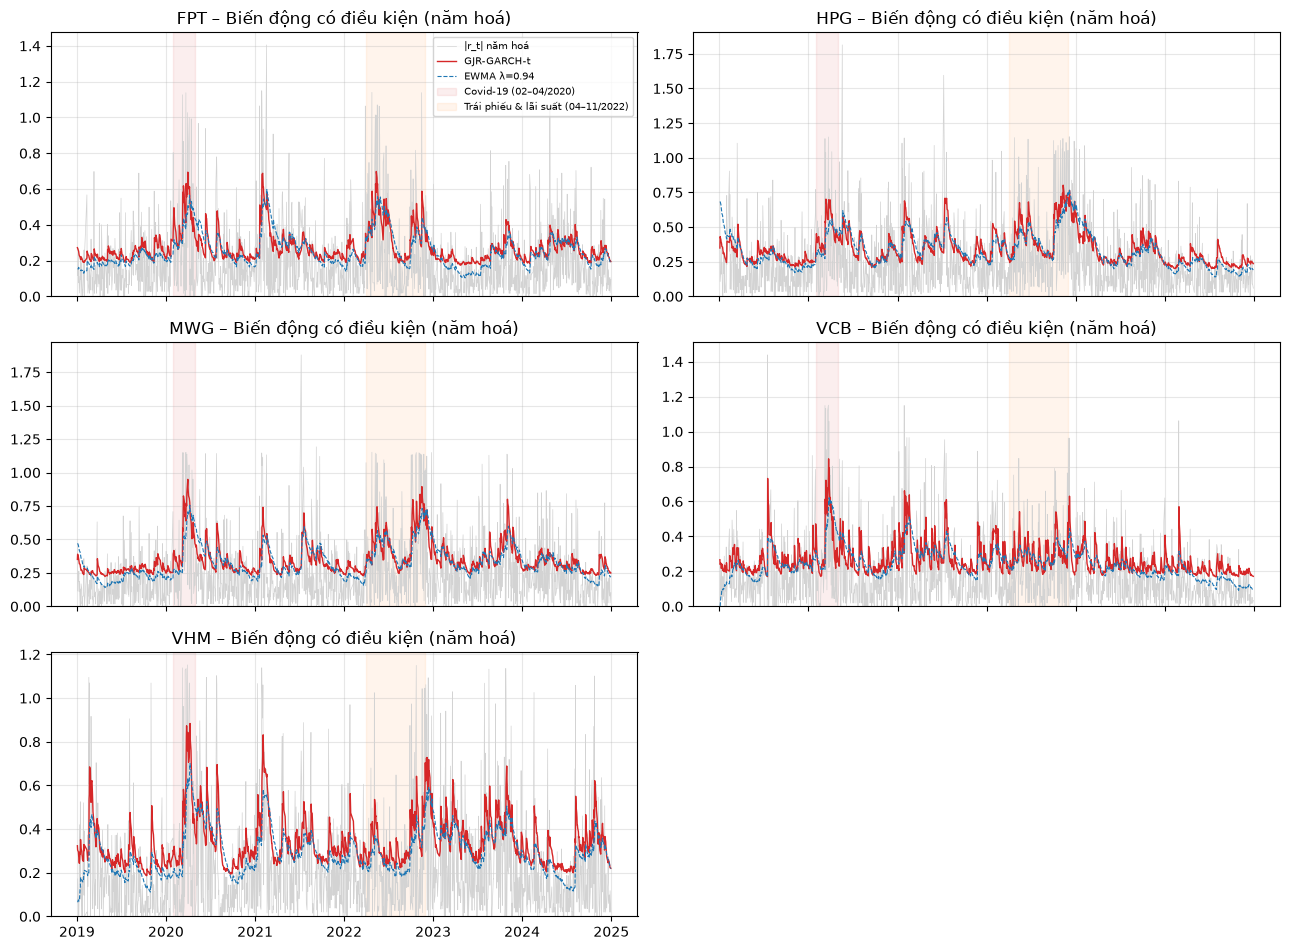

In [7]:
# Biểu đồ biến động có điều kiện (năm hoá) – so sánh với EWMA (RiskMetrics, λ = 0.94)
LAMBDA = 0.94
ewma = log_ret.pow(2).ewm(alpha=1 - LAMBDA, adjust=False).mean().shift(1).pipe(np.sqrt)
ncol = 2
nrow = int(np.ceil(len(tickers) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.2 * nrow), sharex=True, squeeze=False)
for ax, tk in zip(axes.flat, tickers):
    ax.plot(log_ret.index, log_ret[tk].abs() * np.sqrt(TRADING_DAYS), color="lightgrey", lw=0.5, label="|r_t| năm hoá")
    ax.plot(cond_vol.index, cond_vol[tk] * np.sqrt(TRADING_DAYS), color="tab:red", lw=1, label=best.loc[tk, "Mô hình"])
    ax.plot(ewma.index, ewma[tk] * np.sqrt(TRADING_DAYS), color="tab:blue", lw=0.8, ls="--", label="EWMA λ=0.94")
    shade_stress(ax, alpha=0.08)
    ax.set_title(f"{tk} – Biến động có điều kiện (năm hoá)")
    ax.set_ylim(0, None); ax.grid(alpha=0.3)
for ax in axes.flat[len(tickers):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=7, loc="upper right")
plt.tight_layout()
plt.savefig(OUT_DIR / "conditional_volatility.png", dpi=150, bbox_inches="tight")
plt.show()

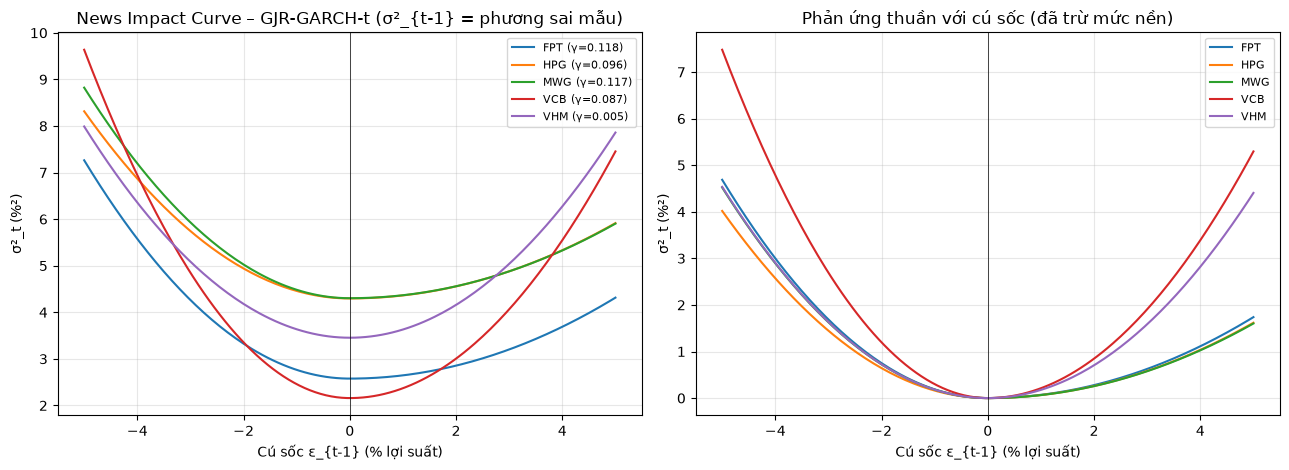

In [8]:
# News Impact Curve: σ²_t phản ứng thế nào với cú sốc ε_{t-1} (GJR: bất đối xứng)
# Sửa lỗi: giữ σ²_{t-1} cố định tại PHƯƠNG SAI MẪU của từng mã (thay vì ω/(1-persistence),
# vốn nổ tung khi persistence ≈ 1 như VHM) -> các đường không còn bị "ép phẳng".
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
shocks = np.linspace(-5, 5, 201)                      # ε_{t-1}, đơn vị % lợi suất

for tk in tickers:
    f = fits[(tk, "GJR-GARCH-t")]["params"]
    sig2_ref = (log_ret[tk].dropna() * SCALE).var()   # σ²_{t-1} cố định = phương sai mẫu (%²)
    nic = f["omega"] + (f["alpha"] + f["gamma"] * (shocks < 0)) * shocks ** 2 + f["beta"] * sig2_ref
    axes[0].plot(shocks, nic, label=f"{tk} (γ={f['gamma']:.3f})")
    # Panel phải: chỉ phần phản ứng với cú sốc (bỏ hằng số) để so sánh độ cong/bất đối xứng
    axes[1].plot(shocks, nic - nic.min(), label=tk)

axes[0].set_title("News Impact Curve – GJR-GARCH-t (σ²_{t-1} = phương sai mẫu)")
axes[1].set_title("Phản ứng thuần với cú sốc (đã trừ mức nền)")
for ax in axes:
    ax.axvline(0, color="k", lw=0.5)
    ax.set_xlabel("Cú sốc ε_{t-1} (% lợi suất)"); ax.set_ylabel("σ²_t (%²)")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUT_DIR / "news_impact_curve.png", dpi=150)
plt.show()

## 4. Chẩn đoán phần dư (Residual Diagnostics)

**Tầng 1:** Ljung-Box trên ε kiểm tra tự tương quan còn sót trong phương trình trung bình; Ljung-Box trên ε² kiểm tra **hiệu ứng ARCH còn sót**.
So sánh với Ljung-Box trên $r_t^2$ của TV1 (p ≈ 0): nếu p-value của ε² > 0,05 ⇒ GARCH đã "hấp thụ" cụm biến động.

**Tầng 3:** Ô xanh = p ≥ 0,05 (đạt yêu cầu). Ô đỏ ở ε (nhưng xanh ở ε²) thường do tự tương quan bậc thấp của lợi suất (VCB/VHM ở TV1) – có thể bổ sung AR(1) vào phương trình trung bình nếu cần.

In [12]:
# ===================== 4. LJUNG-BOX TRÊN ε VÀ ε² =====================
diag_rows = []
for tk in tickers:
    for label, series in [("r_t² (trước GARCH)", log_ret[tk] ** 2), ("ε", std_resid[tk]), ("ε²", std_resid[tk] ** 2)]:
        lb = ljung_box(series, LB_LAGS)
        for lag, row in lb.iterrows():
            diag_rows.append({"Mã": tk, "Chuỗi": label, "Lag": lag, "Q": row["Q"], "p-value": row["p-value"]})
diagnostics = pd.DataFrame(diag_rows)
diag_pivot = diagnostics.pivot_table(index=["Mã", "Chuỗi"], columns="Lag", values="p-value", sort=False)
diag_pivot.columns = [f"p (lag {c})" for c in diag_pivot.columns]
def lb_color(v):
    if v < ALPHA:   # p < 0,05: còn tự tương quan / hiệu ứng ARCH
        return "background-color: #c0392b; color: white; font-weight: bold"
    return "background-color: #1e8449; color: white"   # p >= 0,05: đạt

sty = diag_pivot.style.format("{:.4f}")
sty_map = getattr(sty, "map", None) or sty.applymap
display(sty_map(lb_color))
diagnostics.to_csv(OUT_DIR / "residual_diagnostics.csv", index=False, encoding="utf-8-sig")

max_lag = max(LB_LAGS)
ok = diagnostics[(diagnostics["Chuỗi"] == "ε²") & (diagnostics["Lag"] == max_lag)].set_index("Mã")["p-value"]
print(f"Hiệu ứng ARCH còn sót (ε², lag {max_lag}): " +
      ", ".join(f"{tk}={'CÒN' if p < ALPHA else 'đã loại bỏ'} (p={p:.3f})" for tk, p in ok.items()))

Hiệu ứng ARCH còn sót (ε², lag 20): FPT=đã loại bỏ (p=0.088), HPG=đã loại bỏ (p=0.815), MWG=đã loại bỏ (p=0.955), VCB=đã loại bỏ (p=0.991), VHM=đã loại bỏ (p=0.926)


In [10]:
# ===================== LƯU EXCEL TỔNG HỢP =====================
with pd.ExcelWriter(OUT_DIR / "TV2_garch_results.xlsx", engine="openpyxl") as xw:
    selected_df.to_excel(xw, sheet_name="Mo_hinh_chon")
    comparison.to_excel(xw, sheet_name="So_sanh_AIC_BIC", index=False)
    lr_table.to_excel(xw, sheet_name="LR_GJR_vs_GARCH", index=False)
    all_params.to_excel(xw, sheet_name="Tham_so_day_du", index=False)
    diagnostics.to_excel(xw, sheet_name="Ljung_Box_phan_du", index=False)
print("✔ Đã lưu kết quả TV2 vào:", OUT_DIR)

✔ Đã lưu kết quả TV2 vào: D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV2_GARCH


## 5. Diễn giải cốt lõi – vai trò của GARCH đơn biến trong DCC hai bước

DCC-GARCH (Engle, 2002) tách log-likelihood thành **phần biến động** + **phần tương quan**:
1. **Bước 1 (TV2):** ước lượng GARCH riêng cho từng mã ⇒ có $\sigma_{i,t}$, chuẩn hoá biến động riêng lẻ, loại bỏ phương sai thay đổi.
2. **Bước 2 (TV3):** dùng $\epsilon_{i,t}=(r_{i,t}-\mu_i)/\sigma_{i,t}$ (phương sai ≈ 1, không còn ARCH) làm đầu vào ước lượng tương quan động $R_t$.

Nếu bỏ bước 1, tương quan ước lượng sẽ bị "nhiễu" bởi biến động: hai mã cùng tăng biến động sẽ trông như tương quan tăng.

### Gợi ý trả lời vấn đáp
**Câu 1 – α + β ≈ 1 nghĩa là gì?** Biến động có **độ bền rất cao**: cú sốc hôm nay ảnh hưởng tới biến động nhiều tuần sau (half-life dài); phương sai dài hạn ω/(1−α−β) rất lớn và hội tụ chậm. Khi = 1 là IGARCH (giống EWMA) – cú sốc không bao giờ tắt.

**Câu 2 – Hiệu ứng đòn bẩy ở thị trường Việt Nam?** γ > 0 ⇒ phiên giảm điểm làm biến động phiên sau tăng mạnh hơn phiên tăng cùng biên độ. Ở VN, nhà đầu tư cá nhân chiếm tỷ trọng lớn, dùng margin nhiều: giá giảm ⇒ call margin ⇒ bán giải chấp dây chuyền ⇒ biến động tăng (rõ nhất 2022). Về quản trị rủi ro: VaR cần phản ứng nhanh hơn sau phiên giảm mạnh.

Rolling: WINDOW = 952 ngày, REFIT = 20, N_TEST = 500 (2022-12-22 -> 2024-12-30)
✔ FPT: xong (8s)
✔ HPG: xong (15s)
✔ MWG: xong (25s)
✔ VCB: xong (37s)
✔ VHM: xong (46s)


Mô hình,GARCH-N,GARCH-t,GJR-GARCH-N,GJR-GARCH-t,EWMA
Mã,,,,,
FPT,1.6707,1.8271,1.6937,1.7077,1.6657
HPG,1.5660,1.5852,1.5730,1.6475,1.5871
MWG,1.6280,1.6453,1.6097,1.6729,1.6332
VCB,1.7437,1.8832,1.7115,1.9622,1.6250
VHM,2.0063,1.9355,1.9478,1.9381,2.1238


Ô xanh = QLIKE nhỏ nhất (dự báo tốt nhất) của từng mã.
  FPT: tốt nhất ngoài mẫu = EWMA         | chọn theo BIC = GJR-GARCH-t  -> KHÁC
  HPG: tốt nhất ngoài mẫu = GARCH-N      | chọn theo BIC = GJR-GARCH-t  -> KHÁC
  MWG: tốt nhất ngoài mẫu = GJR-GARCH-N  | chọn theo BIC = GJR-GARCH-t  -> KHÁC
  VCB: tốt nhất ngoài mẫu = EWMA         | chọn theo BIC = GARCH-t      -> KHÁC
  VHM: tốt nhất ngoài mẫu = GARCH-t      | chọn theo BIC = GARCH-t      -> TRÙNG


,Mã,A,B,DM (QLIKE),p-value,Kết luận
0,FPT,GJR-GARCH-t,GARCH-N,1.0943,0.2738,Không khác biệt có ý nghĩa
1,FPT,GJR-GARCH-t,GARCH-t,-2.1994,0.0279,GJR-GARCH-t tốt hơn
2,FPT,GARCH-t,GARCH-N,2.9774,0.0029,GARCH-N tốt hơn
3,FPT,GJR-GARCH-t,EWMA,0.8149,0.4151,Không khác biệt có ý nghĩa
4,HPG,GJR-GARCH-t,GARCH-N,2.1843,0.0289,GARCH-N tốt hơn
5,HPG,GJR-GARCH-t,GARCH-t,2.5658,0.0103,GARCH-t tốt hơn
6,HPG,GARCH-t,GARCH-N,1.1850,0.2360,Không khác biệt có ý nghĩa
7,HPG,GJR-GARCH-t,EWMA,1.2345,0.2170,Không khác biệt có ý nghĩa
8,MWG,GJR-GARCH-t,GARCH-N,1.4095,0.1587,Không khác biệt có ý nghĩa
9,MWG,GJR-GARCH-t,GARCH-t,1.4905,0.1361,Không khác biệt có ý nghĩa


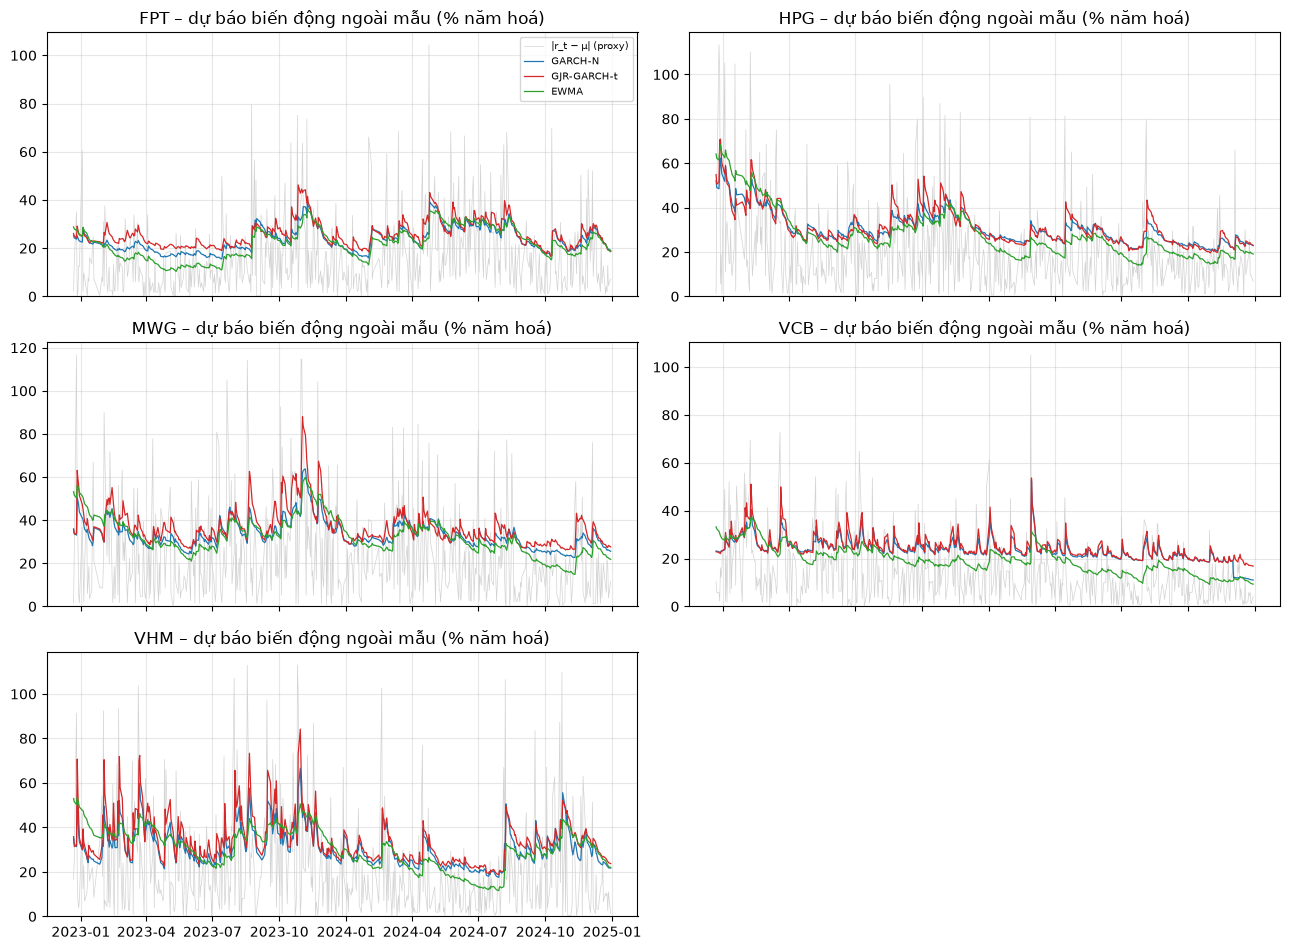

✔ Đã lưu kết quả ngoài mẫu TV2 vào: D:\Năm 3\Ứng dụng công nghệ trong TCNH\final\output\TV2_GARCH


In [13]:
# CODE THÊM CHO THÀNH VIÊN 2 (Như) – SO SÁNH MÔ HÌNH BIẾN ĐỘNG NGOÀI MẪU
# Cách dùng: dán vào CUỐI notebook TV2_GARCH.ipynb, mỗi khối "# %%" là 1 ô (cell).
# Cần các ô phía trên đã chạy: fit_garch, SPECS, SCALE, log_ret, tickers, selected_df, OUT_DIR.
# =====================================================================================

# %% [markdown]
# ## 6. So sánh mô hình ngoài mẫu (Out-of-sample volatility forecasting)
#
# **Tầng 1 – Ý tưởng & công thức**
# AIC/BIC ở mục 2 chỉ đo độ khớp **trong mẫu**. Đề bài yêu cầu so sánh ít nhất 2 mô hình **ngoài mẫu**:
# - **Rolling window:** với mỗi ngày kiểm định $t$ (`N_TEST` ngày cuối), dự báo $\hat\sigma^2_t$ chỉ dùng dữ liệu đến $t-1$.
#   Tham số được ước lượng lại mỗi `REFIT` ngày trên `WINDOW` ngày gần nhất; giữa hai lần ước lượng, giữ nguyên tham số và lọc (filter) tiếp $\sigma^2_t$.
# - **Đại lượng thay thế (proxy)** cho phương sai thật (không quan sát được): $\tilde\sigma^2_t = (r_t-\hat\mu)^2$.
# - **Hàm mất mát:** $MSE = \frac1n\sum(\tilde\sigma^2_t-\hat\sigma^2_t)^2$; $QLIKE = \frac1n\sum\left(\frac{\tilde\sigma^2_t}{\hat\sigma^2_t}-\ln\frac{\tilde\sigma^2_t}{\hat\sigma^2_t}-1\right)$.
#   QLIKE ít bị chi phối bởi vài ngày cực đoan và vẫn xếp hạng đúng mô hình dù proxy nhiễu (Patton, 2011) ⇒ **dùng QLIKE làm tiêu chí chính**.
# - **Kiểm định Diebold–Mariano (DM):** $d_t = L_t^{A} - L_t^{B}$; $DM = \bar d / \sqrt{\widehat{\mathrm{Var}}_{NW}(\bar d)} \sim N(0,1)$. DM < 0 và p < 0,05 ⇒ mô hình A dự báo tốt hơn B có ý nghĩa thống kê.
# - **EWMA (RiskMetrics, λ = 0,94)** làm mô hình chuẩn đơn giản (không cần ước lượng).
#
# **Tầng 2:** `garch_filter_fixed` lọc σ² với tham số cố định, σ²₀ = phương sai của **cửa sổ ước lượng** (không nhìn trước). `rolling_vol_forecast` trả về chuỗi $\hat\sigma^2_t$ cho các ngày kiểm định.
# Output: `oos_vol_forecasts.csv`, `oos_vol_loss.csv`, `oos_dm_test.csv`.
#
# **Tầng 3:** Mô hình có QLIKE nhỏ nhất (hạng 1) dự báo biến động tốt nhất. So sánh với mô hình được chọn theo BIC ở mục 2: nếu trùng ⇒ lựa chọn trong mẫu được xác nhận ngoài mẫu.

# %%
# ===================== 6.1 CẤU HÌNH & HÀM DỰ BÁO ROLLING =====================
N_TEST = 500                                   # số ngày kiểm định cuối mẫu (giống template)
REFIT = 20                                     # ước lượng lại mỗi 20 phiên
WINDOW = min(1000, len(log_ret) - N_TEST)      # cửa sổ ước lượng (tự thu nhỏ nếu mẫu ngắn)
LAMBDA_EWMA = 0.94
print(f"Rolling: WINDOW = {WINDOW} ngày, REFIT = {REFIT}, N_TEST = {N_TEST} "
      f"({log_ret.index[-N_TEST].date()} -> {log_ret.index[-1].date()})")


def garch_filter_fixed(p: dict, r, gjr, n_window):
    """σ²_t với tham số p cố định trên chuỗi r (đã x SCALE); σ²_0 tính từ n_window quan sát đầu (cửa sổ ước lượng)."""
    eps = r - p["mu"]
    bc = np.mean(eps[:n_window] ** 2)
    g = p.get("gamma", 0.0) if gjr else 0.0
    x = np.empty_like(eps)
    x[0] = p["omega"] + (p["alpha"] + 0.5 * g) * bc + p["beta"] * bc
    x[1:] = p["omega"] + (p["alpha"] + g * (eps[:-1] < 0)) * eps[:-1] ** 2
    return lfilter([1.0], [1.0, -p["beta"]], x)


def rolling_vol_forecast(r_all, spec):
    """r_all: lợi suất 1 mã (x SCALE). Trả về (σ̂²_t, μ̂_t) cho N_TEST ngày cuối, mỗi ngày chỉ dùng dữ liệu đến t-1."""
    T = len(r_all)
    s2_out, mu_out = np.empty(N_TEST), np.empty(N_TEST)
    for start in range(T - N_TEST, T, REFIT):
        end = min(start + REFIT, T)
        f = fit_garch(r_all[start - WINDOW:start], **spec)            # ước lượng trên cửa sổ [start-WINDOW, start)
        s2 = garch_filter_fixed(f["params"], r_all[start - WINDOW:end], spec["gjr"], WINDOW)
        k = slice(start - (T - N_TEST), end - (T - N_TEST))
        s2_out[k] = s2[WINDOW:]                                      # σ²_t của ngày t dùng ε đến t-1
        mu_out[k] = f["params"]["mu"]
    return s2_out, mu_out


def ewma_forecast(r_all):
    """EWMA: σ²_t = λσ²_{t-1} + (1-λ) r²_{t-1}; khởi tạo bằng phương sai cửa sổ đầu tiên."""
    T = len(r_all)
    s2 = np.empty(T)
    s2[0] = np.var(r_all[:WINDOW])
    for t in range(1, T):
        s2[t] = LAMBDA_EWMA * s2[t - 1] + (1 - LAMBDA_EWMA) * r_all[t - 1] ** 2
    return s2[-N_TEST:]

# %%
# ===================== 6.2 CHẠY DỰ BÁO CHO TẤT CẢ MÃ & MÔ HÌNH =====================
import time
test_idx = log_ret.index[-N_TEST:]
oos = {}                                         # oos[(mã, mô hình)] = DataFrame(var_fcst, proxy)
t0 = time.time()
for tk in tickers:
    r_all = log_ret[tk].values * SCALE
    for name, spec in SPECS.items():
        s2, mu_hat = rolling_vol_forecast(r_all, spec)
        oos[(tk, name)] = pd.DataFrame({"var_fcst": s2, "proxy": (r_all[-N_TEST:] - mu_hat) ** 2}, index=test_idx)
    mu_ew = np.mean(r_all[:len(r_all) - N_TEST][-WINDOW:])
    oos[(tk, "EWMA")] = pd.DataFrame({"var_fcst": ewma_forecast(r_all),
                                      "proxy": (r_all[-N_TEST:] - mu_ew) ** 2}, index=test_idx)
    print(f"✔ {tk}: xong ({time.time() - t0:.0f}s)")

oos_vol = pd.concat({f"{tk}|{m}": np.sqrt(d["var_fcst"]) / SCALE for (tk, m), d in oos.items()}, axis=1)
oos_vol.index.name = "Date"
oos_vol.to_csv(OUT_DIR / "oos_vol_forecasts.csv", encoding="utf-8-sig")   # σ̂ dự báo (thập phân/ngày)

# %%
# ===================== 6.3 HÀM MẤT MÁT MSE & QLIKE =====================
def losses(d):
    p, f = d["proxy"].clip(lower=1e-8), d["var_fcst"]
    return pd.DataFrame({"MSE": (d["proxy"] - f) ** 2, "QLIKE": p / f - np.log(p / f) - 1})


loss_rows = []
for (tk, m), d in oos.items():
    L = losses(d).mean()
    loss_rows.append({"Mã": tk, "Mô hình": m, "MSE": L["MSE"], "QLIKE": L["QLIKE"]})
oos_loss = pd.DataFrame(loss_rows)
oos_loss["Hạng QLIKE"] = oos_loss.groupby("Mã")["QLIKE"].rank().astype(int)
oos_loss["Hạng MSE"] = oos_loss.groupby("Mã")["MSE"].rank().astype(int)
oos_loss["Chọn theo BIC (mục 2)"] = [selected_df.loc[tk, "Model"] == m for tk, m in zip(oos_loss["Mã"], oos_loss["Mô hình"])]

qlike_table = oos_loss.pivot(index="Mã", columns="Mô hình", values="QLIKE")[list(SPECS) + ["EWMA"]]
sty = (qlike_table.style.format("{:.4f}")
       .highlight_min(axis=1, props="background-color: #1e8449; color: white; font-weight: bold"))
display(sty)
print("Ô xanh = QLIKE nhỏ nhất (dự báo tốt nhất) của từng mã.")
best_oos = qlike_table.idxmin(axis=1)
for tk in tickers:
    same = "TRÙNG" if best_oos[tk] == selected_df.loc[tk, "Model"] else "KHÁC"
    print(f"  {tk}: tốt nhất ngoài mẫu = {best_oos[tk]:<12} | chọn theo {SELECT_BY} = {selected_df.loc[tk, 'Model']:<12} -> {same}")
oos_loss.to_csv(OUT_DIR / "oos_vol_loss.csv", index=False, encoding="utf-8-sig")

# %%
# ===================== 6.4 KIỂM ĐỊNH DIEBOLD-MARIANO =====================
def diebold_mariano(la, lb, h=1):
    """H0: hai mô hình dự báo tốt như nhau. DM < 0 => mô hình A có loss nhỏ hơn. Phương sai Newey-West."""
    d = np.asarray(la) - np.asarray(lb)
    n = len(d)
    dc = d - d.mean()
    lag = max(h - 1, int(np.floor(n ** (1 / 3))))
    v = dc @ dc / n
    for k in range(1, lag + 1):
        v += 2 * (1 - k / (lag + 1)) * (dc[k:] @ dc[:-k]) / n
    dm = d.mean() / np.sqrt(v / n)
    return dm, 2 * stats.norm.sf(abs(dm))


PAIRS = [("GJR-GARCH-t", "GARCH-N"), ("GJR-GARCH-t", "GARCH-t"), ("GARCH-t", "GARCH-N"), ("GJR-GARCH-t", "EWMA")]
dm_rows = []
for tk in tickers:
    for A, B in PAIRS:
        la, lb = losses(oos[(tk, A)])["QLIKE"], losses(oos[(tk, B)])["QLIKE"]
        dm, p = diebold_mariano(la, lb)
        verdict = (f"{A} tốt hơn" if dm < 0 else f"{B} tốt hơn") if p < ALPHA else "Không khác biệt có ý nghĩa"
        dm_rows.append({"Mã": tk, "A": A, "B": B, "DM (QLIKE)": dm, "p-value": p, "Kết luận": verdict})
dm_table = pd.DataFrame(dm_rows)
display(dm_table.round(4))
dm_table.to_csv(OUT_DIR / "oos_dm_test.csv", index=False, encoding="utf-8-sig")

# %%
# ===================== 6.5 ĐỒ THỊ DỰ BÁO NGOÀI MẪU =====================
ncol = 2
nrow = int(np.ceil(len(tickers) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.2 * nrow), sharex=True, squeeze=False)
for ax, tk in zip(axes.flat, tickers):
    ann = np.sqrt(TRADING_DAYS) / SCALE * 100
    ax.plot(test_idx, np.sqrt(oos[(tk, "GARCH-N")]["proxy"]) * ann, color="lightgrey", lw=0.5, label="|r_t − μ| (proxy)")
    for m, c in [("GARCH-N", "tab:blue"), ("GJR-GARCH-t", "tab:red"), ("EWMA", "tab:green")]:
        ax.plot(test_idx, np.sqrt(oos[(tk, m)]["var_fcst"]) * ann, lw=0.9, color=c, label=m)
    ax.set_title(f"{tk} – dự báo biến động ngoài mẫu (% năm hoá)"); ax.grid(alpha=0.3); ax.set_ylim(0, None)
for ax in axes.flat[len(tickers):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(OUT_DIR / "oos_vol_forecasts.png", dpi=150, bbox_inches="tight"); plt.show()

with pd.ExcelWriter(OUT_DIR / "TV2_out_of_sample.xlsx", engine="openpyxl") as xw:
    qlike_table.to_excel(xw, sheet_name="QLIKE")
    oos_loss.to_excel(xw, sheet_name="Loss_day_du", index=False)
    dm_table.to_excel(xw, sheet_name="Diebold_Mariano", index=False)
print("✔ Đã lưu kết quả ngoài mẫu TV2 vào:", OUT_DIR)

# %% [markdown]
# **Diễn giải (gợi ý viết mục 6.1):** Bảng QLIKE cho biết mô hình nào dự báo biến động 1 ngày tốt nhất ngoài mẫu; kiểm định DM cho biết khác biệt có ý nghĩa thống kê hay không.
# Nếu GJR-t thắng ⇒ hiệu ứng đòn bẩy và đuôi dày không chỉ khớp trong mẫu mà còn **cải thiện dự báo** – cơ sở để dùng GJR-t làm mô hình biên cho DCC (TV3) và VaR (TV4).
# Nếu khác biệt không có ý nghĩa ⇒ nói rõ trong báo cáo: các mô hình GARCH cho dự báo tương đương, ưu tiên mô hình theo BIC vì gọn hơn.
# *Giới hạn:* $r_t^2$ là proxy rất nhiễu của phương sai thật; nếu có dữ liệu trong ngày, realised variance sẽ là proxy tốt hơn.